### Библиотеки / данные

In [94]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy import stats
from scipy.stats import norm
###  see 
### https://docs.scipy.org/doc/scipy/reference/stats.html

In [99]:
################ READ from the file

In [111]:
import os
#os.listdir()

In [112]:
print(os.getcwd())
path="C:\\Users\\admin\\Downloads\\LABORATORKI"
os.chdir(path)
os.getcwd()
###os.listdir(path)

C:\Users\admin\Downloads\LABORATORKI


'C:\\Users\\admin\\Downloads\\LABORATORKI'

In [115]:
doc=pd.read_excel("data_lab_3/PFO_doctors_2000_2018.xlsx",sheet_name='PFO')
doc.head()

,год,Приволжский федеральный округ,Республика Татарстан,Оренбургская область,Самарская область,Саратовская область,Ульяновская область
0,2000,45.9,44.2,48.7,47.8,49.4,36.6
1,2001,45.7,44.1,49.0,47.2,49.3,36.9
2,2002,46.0,44.7,49.4,47.6,49.8,37.4
3,2003,46.3,45.4,50.0,47.7,50.2,35.9
4,2004,46.6,44.9,50.3,48.6,50.7,35.7


In [103]:
god=doc["год"]

In [104]:
doc["Республика Татарстан"]

0     44.2
1     44.1
2     44.7
3     45.4
4     44.9
5     44.9
6     45.2
7     44.8
8     43.0
9     43.9
10    44.2
11    44.2
12    41.9
13    41.4
14    42.1
15    40.6
16    40.2
17    41.5
18    42.2
Name: Республика Татарстан, dtype: float64

In [116]:
doc["Саратовская область"]

0     49.4
1     49.3
2     49.8
3     50.2
4     50.7
5     52.7
6     52.5
7     52.2
8     52.4
9     51.8
10    52.0
11    53.0
12    52.8
13    53.5
14    53.2
15    48.6
16    48.0
17    50.4
18    50.5
Name: Саратовская область, dtype: float64

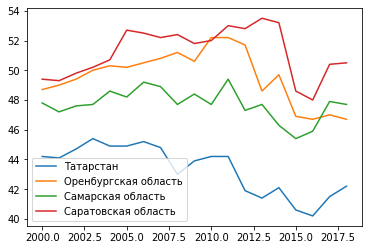

In [117]:
### Визуализация данных - графики
plt.plot(god,doc["Республика Татарстан"])
plt.plot(god,doc["Оренбургская область"])
plt.plot(god,doc["Самарская область"])
plt.plot(god,doc["Саратовская область"])
plt.legend(["Татарстан", "Оренбургская область","Самарская область","Саратовская область"])

In [106]:
X_tatarstan=doc["Республика Татарстан"]
X_Samara=doc["Самарская область"]
X_Oren=doc["Оренбургская область"]
X_Saratov=doc["Саратовская область"]

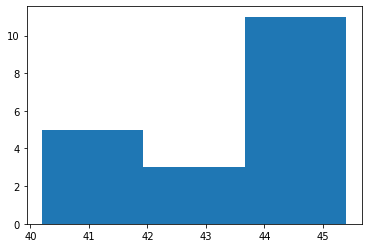

In [107]:
f_obs, bins, ignored = plt.hist(X_tatarstan,3)

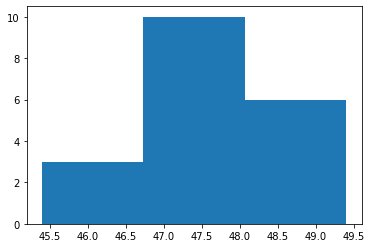

In [108]:
f_obs, bins, ignored = plt.hist(X_Samara,3)

In [109]:
rez=stats.shapiro(X_tatarstan)
print(rez)

ShapiroResult(statistic=0.9011173248291016, pvalue=0.05097231641411781)


In [83]:
rez=stats.shapiro(X_Samara)
print(rez)

ShapiroResult(statistic=0.9353136420249939, pvalue=0.21679607033729553)


In [84]:
rez=stats.shapiro(X_Oren)
print(rez)

ShapiroResult(statistic=0.9283690452575684, pvalue=0.16160203516483307)


In [85]:
rez=stats.shapiro(X_Saratov)
print(rez)

ShapiroResult(statistic=0.9335408210754395, pvalue=0.20119255781173706)


In [86]:
res = stats.bartlett(X_tatarstan,X_Samara,X_Oren, X_Saratov)
res

BartlettResult(statistic=5.751812629750622, pvalue=0.12432960790851283)

In [119]:
alpha=0.05
X_tatarstan=doc["Республика Татарстан"]
## print(X_tatarstan)
mean_tatarstan=np.mean(X_tatarstan)
std_tatarstan=np.std(X_tatarstan,ddof=1)
a_0=np.mean(doc["Приволжский федеральный округ"])
(mean_tatarstan,a_0,std_tatarstan)


(43.336842105263166, 46.473684210526315, 1.6533503111748542)

In [89]:
### H_0: M(X_tatarstan) = a_0
### H_1: M(X_tatarstan) < a_0
############################################
### If pvalue>alpha => H_0 adopted
### If pvalue<=alpha => H_0 rejected and H_1 adopted

n=len(X_tatarstan)
T_nabl=(mean_tatarstan-a_0)/std_tatarstan*math.sqrt(n)
p_value=stats.t.cdf(T_nabl,df=n-1)
print(T_nabl,p_value)

-8.26998225740159 7.613533966900695e-08


In [120]:
res=stats.ttest_1samp(X_tatarstan,popmean=a_0,alternative='less')
print(res)

Ttest_1sampResult(statistic=-8.26998225740159, pvalue=7.613533966900695e-08)


In [121]:
X_tatarstan=doc["Республика Татарстан"]
X_Samara=doc["Самарская область"]
(np.mean(X_tatarstan),np.mean(X_Samara))

(43.336842105263166, 47.715789473684204)

In [122]:
(np.var(X_tatarstan),np.var(X_Samara))

(2.589695290858725, 1.00448753462604)

In [123]:
alpha=0.05
### H_0: D(X_tatarstan) = D(X_Samara)
### H_1: D(X_tatarstan) > D(X_Samara)
res = stats.bartlett(X_tatarstan,X_Samara)
res

BartlettResult(statistic=3.7885448926851737, pvalue=0.05160449172372676)

In [124]:
###############
###### На предыдущем шаге выяснили, что  гипотеза
## H_0: D(X_tatarstan) = D(X_Samara)  согласуется с данными выборок
### Поэтому можно проверить гипотезу о равенстве средних с помощью T-критерия
alpha=0.05
### H_0: M(X_tatarstan) = M(X_Samara)
### H_1: M(X_tatarstan) <  M(X_Samara)
############################################
### If pvalue>alpha => H_0 adopted
### If pvalue<=alpha => H_0 rejected and H_1 adopted
res=stats.ttest_ind(X_tatarstan,X_Samara,alternative='less')
print(res) 

Ttest_indResult(statistic=-9.799544639650781, pvalue=5.3205976761527e-12)


In [125]:
### H_0: M(X_Samara)= M(X_tatarstan) 
### H_1:  M(X_Samara) > M(X_tatarstan)
############################################
### If pvalue>alpha => H_0 adopted
### If pvalue<=alpha => H_0 rejected and H_1 adopted
alpha=0.05
res=stats.ttest_ind(X_Samara,X_tatarstan,alternative='greater')
print(res)

Ttest_indResult(statistic=9.799544639650781, pvalue=5.3205976761527e-12)


In [126]:
res=stats.ttest_ind(X_tatarstan,X_Samara)
print(res)

Ttest_indResult(statistic=-9.799544639650781, pvalue=1.06411953523054e-11)


In [93]:
res=stats.ttest_ind(X_Samara,X_tatarstan,alternative='less')
print(res) 

Ttest_indResult(statistic=9.799544639650781, pvalue=0.9999999999946794)
